<a href="https://colab.research.google.com/github/Suu-mnw/Applied-Data-Science-1/blob/main/ADS1_Tutorial_4_1_Basic_Statistics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Name**

# Statistics for Data Science — Practice
**ADS 1 (7FTC2002) ·

This notebook goes with the lecture slides. It has four parts that match the lecture, three short Practice and a case Study:

| Part | Topic | Practice |
|---|---|---|
| 1 | Describing data | Practice 1 · summarise *tips*, hunt outliers (10 min) |
| 2 | Distributions | Practice 2 · fit and check supplier lead times (10 min) |
| 3 | Sampling and inference | Practice 3 · CLT, CI coverage, bootstrap (10 min) |
| 4 | Hypothesis testing | demos only |
| 5 | Relationships | demos only |
| ★ | Case Study | Should we switch to Supplier B? (20 min) |

Run the two setup cells first. Cells marked **`# TODO`** are yours to complete.

## 0 · Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.power import TTestIndPower
from statsmodels.stats.multitest import multipletests

sns.set_theme(style="whitegrid", context="notebook")
rng = np.random.default_rng(42)   # one generator for every simulation below

In [2]:
# Dataset 1: restaurant tips (ships with seaborn)
tips = sns.load_dataset("tips")

# Dataset 2: supplier lead times in days (simulated, reproducible)
def make_lead_times(seed=55):
    r = np.random.default_rng(seed)
    # 2,000 historical orders from Supplier A
    history = pd.DataFrame({"lead_time_days": r.lognormal(np.log(10), 0.25, 2000).round(1)})
    # 60 recent orders from each supplier
    a = r.lognormal(np.log(10), 0.25, 60)
    fast = r.lognormal(np.log(8.5), 0.20, 60)
    slow = r.lognormal(np.log(15), 0.25, 60)
    b = np.where(r.random(60) < 0.85, fast, slow)   # B is usually fast, sometimes very slow
    orders = pd.DataFrame({"supplier": ["A"] * 60 + ["B"] * 60,
                           "lead_time_days": np.r_[a, b].round(1)})
    return history, orders

history, orders = make_lead_times()
print("tips:", tips.shape, "| history:", history.shape, "| orders:", orders.shape)
orders.head()

tips: (244, 7) | history: (2000, 1) | orders: (120, 2)


,supplier,lead_time_days
0,A,11.3
1,A,7.2
2,A,15.3
3,A,16.2
4,A,14.3


---
## Part 1 · Describing data

### Population or sample? `ddof` decides
pandas divides by *n − 1* by default (sample); NumPy divides by *n* (population).

In [3]:
x = [2, 4, 6]
print("np.std(x)            ", np.std(x))             # ddof=0, ÷n
print("np.std(x, ddof=1)    ", np.std(x, ddof=1))     # ÷(n-1)
print("pd.Series(x).std()   ", pd.Series(x).std())    # pandas default ddof=1

np.std(x)             1.632993161855452
np.std(x, ddof=1)     2.0
pd.Series(x).std()    2.0


### One outlier breaks the mean — and hides itself from the z-score rule

In [4]:
x = pd.Series([2, 4, 6, 8, 200])
q1, q3 = x.quantile([0.25, 0.75])
iqr = q3 - q1
summary = pd.Series({
    "mean": x.mean(), "median": x.median(),
    "std (ddof=1)": x.std(), "IQR": iqr,
    "MAD": stats.median_abs_deviation(x),
})
print(summary.round(2))

z = (x - x.mean()) / x.std()
print("\nz-score of 200:", round(z.iloc[-1], 2), "→ flagged by |z| > 3?", abs(z.iloc[-1]) > 3)
print("IQR upper fence:", q3 + 1.5 * iqr, "→ 200 flagged?", 200 > q3 + 1.5 * iqr)

mean            44.00
median           6.00
std (ddof=1)    87.24
IQR              4.00
MAD              2.00
dtype: float64

z-score of 200: 1.79 → flagged by |z| > 3? False
IQR upper fence: 14.0 → 200 flagged? True


### Shape: skewness and *excess* kurtosis
`df.kurt()` and `scipy.stats.kurtosis()` report **excess** kurtosis (normal ≈ 0, not 3).

In [5]:
normal = pd.Series(rng.normal(size=100_000))
heavy  = pd.Series(rng.laplace(size=100_000))
print("normal: skew %.2f  excess kurt %.2f" % (normal.skew(), normal.kurt()))
print("Laplace: skew %.2f  excess kurt %.2f  (theory: 3, heavier tails)" % (heavy.skew(), heavy.kurt()))

normal: skew 0.01  excess kurt 0.02
Laplace: skew -0.01  excess kurt 3.06  (theory: 3, heavier tails)


### Practice 1 · Summarise *tips* and hunt for outliers (10 min)
1. Run `describe()` on `total_bill` and `tip`. Which is more skewed — and how can you tell from mean vs median alone?
2. Compute `skew()` and `kurt()`. Is either variable heavy-tailed?
3. Flag outliers with the z-score rule (|z| > 3) and the IQR rule. Do they agree?
4. Plot `total_bill` by `day` as a box plot, a violin plot and an ECDF. Which tells you most?

In [8]:
# TODO Q1–Q2
cols = ["total_bill", "tip"]
tips[cols].describe()
tips[cols].agg(["mean", "median", "skew", "kurt"])
#both varibles are positively skewed because their values in greater than 0.Tips is more skewed than total bill.
#Tip is heavy-tailed because its kurt value is 3.64 which is significantly greater than zero.

,total_bill,tip
mean,19.785943,2.998279
median,17.795000,2.900000
skew,1.133213,1.465451
kurt,1.218484,3.648376


In [10]:
# TODO Q3 — complete both rules and compare the counts
def z_outliers(s, k=3):
    z = (s-s.mean())/s.std()           # standardise with the sample SD
    return z.abs()>k        # boolean Series

def iqr_outliers(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s > q3 + k * iqr) | (s < q1 - k * iqr)

for c in cols:
    print(c, "z-rule:", z_outliers(tips[c]).sum(), "| IQR rule:", iqr_outliers(tips[c]).sum())

total_bill z-rule: 4 | IQR rule: 9
tip z-rule: 3 | IQR rule: 9


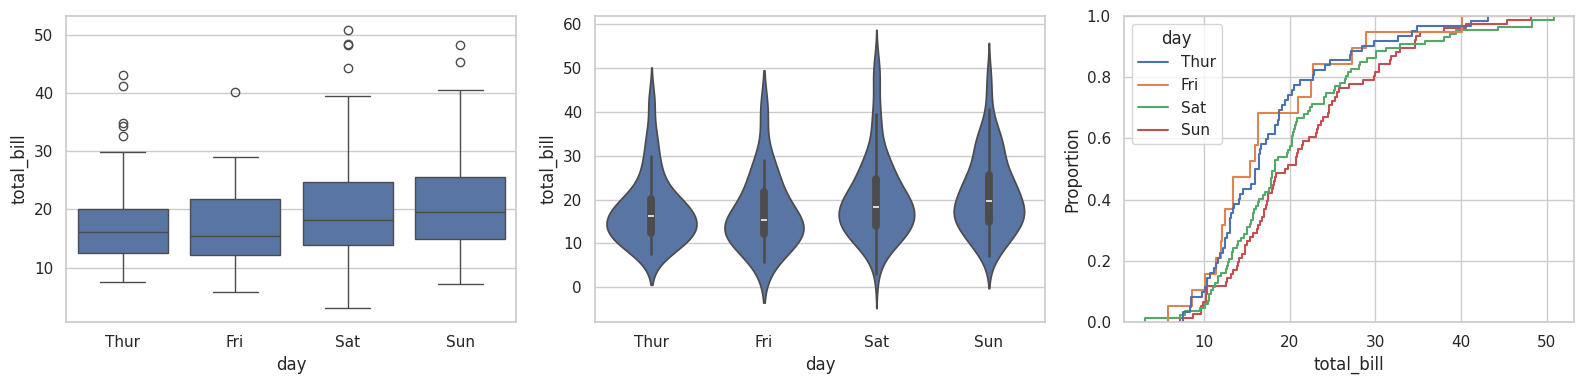

In [13]:
# TODO Q4 — three views of the same comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=tips, x="day", y="total_bill", ax=axes[0])
sns.violinplot(data=tips, x="day", y="total_bill", ax=axes[1])
sns.ecdfplot(data=tips, x="total_bill", hue="day", ax=axes[2])
plt.tight_layout()

---
## Part 2 · Distributions

### The four functions: PMF/PDF, CDF, PPF (and SF)

In [14]:
print("Poisson(3)  P(X=2)        =", round(stats.poisson(3).pmf(2), 3))
print("Normal(0,.25) pdf at 0    =", round(stats.norm(0, 0.25).pdf(0), 3), " ← a density can exceed 1")
print("Normal CDF at 1.96        =", round(stats.norm().cdf(1.96), 3))
print("Normal PPF at 0.975       =", round(stats.norm().ppf(0.975), 3))
print("Normal SF  at 1.96 (1-cdf)=", round(stats.norm().sf(1.96), 3))

Poisson(3)  P(X=2)        = 0.224
Normal(0,.25) pdf at 0    = 1.596  ← a density can exceed 1
Normal CDF at 1.96        = 0.975
Normal PPF at 0.975       = 1.96
Normal SF  at 1.96 (1-cdf)= 0.025


### Frozen distributions and the loc/scale convention
Exponential with rate λ = 2 → `scale = 1/λ`. `moments="mvsk"` returns mean, variance, skew, **excess** kurtosis.

mean, var, skew, excess kurt: [0.5, 0.25, 2.0, 6.0]


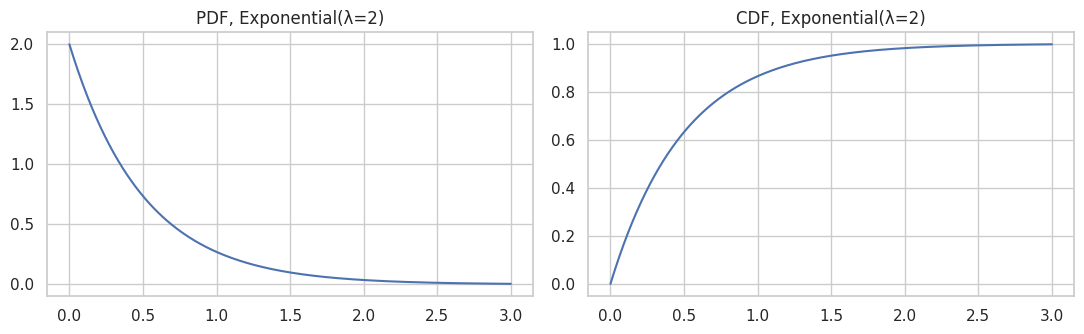

In [15]:
d = stats.expon(scale=1/2)
print("mean, var, skew, excess kurt:", [round(float(v), 3) for v in d.stats(moments="mvsk")])

grid = np.linspace(0, 3, 300)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(grid, d.pdf(grid)); axes[0].set_title("PDF, Exponential(λ=2)")
axes[1].plot(grid, d.cdf(grid)); axes[1].set_title("CDF, Exponential(λ=2)")
plt.tight_layout()

### Practice 2 · Fit and check a distribution for supplier lead times (10 min)
Use `history.lead_time_days` (2,000 orders).
1. Overlay fitted normal and lognormal PDFs on a histogram.
2. Q-Q plot of the raw data against the normal, then of `np.log(lead time)`. What changes?
3. Shapiro–Wilk on 50 rows (`sample(50, random_state=1)`) and on all rows. Why do the verdicts differ?
4. With the lognormal fit: P(lead time > 14 days)? The 95th percentile?

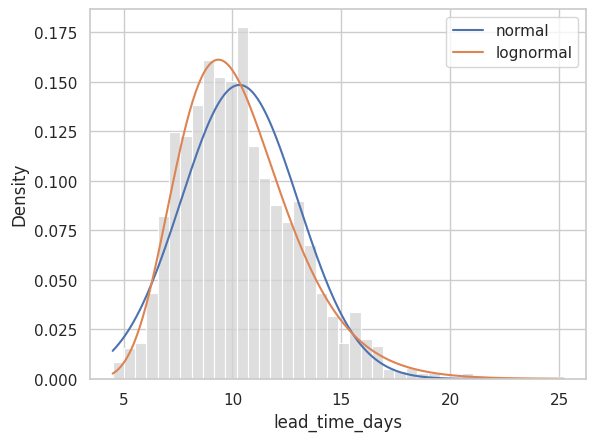

In [16]:
# TODO Q1 — fit both families (hint: stats.norm.fit, stats.lognorm.fit(x, floc=0))
x = history.lead_time_days
mu, sd = stats.norm.fit(x)
s, loc, scale = stats.lognorm.fit(x, floc=0)
grid = np.linspace(x.min(), x.max(), 300)
ax = sns.histplot(x, stat="density", bins=40, color="lightgrey")
ax.plot(grid, stats.norm(mu, sd).pdf(grid), label="normal")
ax.plot(grid, stats.lognorm(s, loc, scale).pdf(grid), label="lognormal")
ax.legend()

((array([-3.39232293, -3.14126578, -3.00201262, ...,  3.00201262,
          3.14126578,  3.39232293]),
  array([1.5040774 , 1.54756251, 1.56861592, ..., 3.10009229, 3.15700042,
         3.22684399])),
 (np.float64(0.25621225084135885),
  np.float64(2.3013310782986367),
  np.float64(0.9996217685591188)))

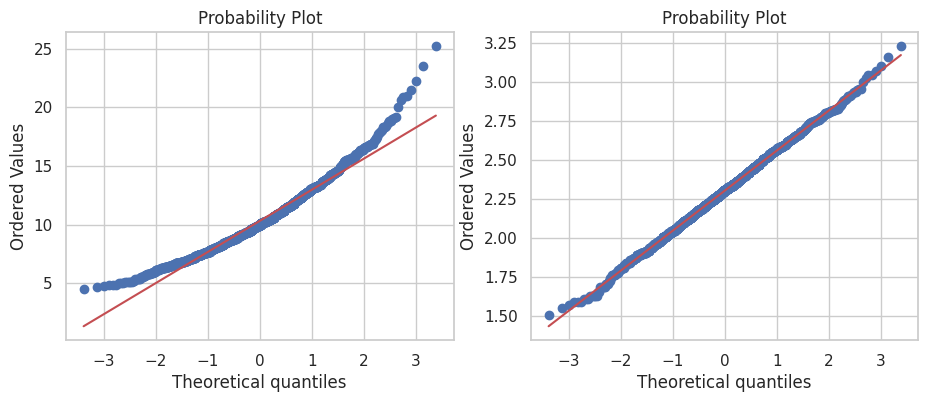

In [17]:
# TODO Q2 — side-by-side Q-Q plots
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
stats.probplot(x, dist="norm", plot=axes[0])
stats.probplot(np.log(x), dist="norm", plot=axes[1])

In [18]:
# TODO Q3
small = x.sample(50, random_state=1)
print("n=50:  ", stats.shapiro(small))
print("n=2000:", stats.shapiro(x))

n=50:   ShapiroResult(statistic=np.float64(0.9776653713704484), pvalue=np.float64(0.45825506275990335))
n=2000: ShapiroResult(statistic=np.float64(0.9668786563077577), pvalue=np.float64(4.9291928832102684e-21))


In [19]:
# TODO Q4 — use the frozen lognormal: .sf() and .ppf()
d = stats.lognorm(s, loc, scale)
print("P(lead time > 14 days):", d.sf(14) )
print("95th percentile (days):", d.ppf(0.95))

P(lead time > 14 days): 0.09347712760084331
95th percentile (days): 15.215064778179514


---
## Part 3 · Sampling and inference

### Practice 3 · See the CLT happen, then quantify uncertainty (10 min)
1. Simulate 10,000 sample means from Exponential(1) for n = 1, 5, 30. Do skew and SD shrink like 2/√n and 1/√n?
2. Build 100 t-intervals (n = 20) from a population with known μ = 50. How many miss?
3. Bootstrap a 95% CI for Supplier A's **median** lead time. Compare it with the t-interval for the **mean**.

In [ ]:
# Provided: a helper to draw many sample means at once
def sample_means(n, reps=10_000):
    return rng.exponential(scale=1.0, size=(reps, n)).mean(axis=1)

In [ ]:
# TODO Q1
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharex=True)
for ax, n in zip(axes, [1, 5, 30]):
    m = sample_means(n)
    # print(n, "skew", ..., "vs", 2/np.sqrt(n), "| SD", ..., "vs", 1/np.sqrt(n))
    # sns.histplot(m, ax=ax, bins=60, stat="density")
plt.tight_layout()

In [ ]:
# TODO Q2 — coverage of 95% t-intervals
mu_true, sigma, n = 50, 10, 20
misses = 0
intervals = []
for i in range(100):
    s = rng.normal(mu_true, sigma, n)
    # lo, hi = stats.t.interval(0.95, df=n-1, loc=..., scale=...)
    # intervals.append((lo, hi)); misses += ...
print("intervals that miss μ:", misses)

In [ ]:
# TODO Q3
a = orders.loc[orders.supplier == "A", "lead_time_days"].to_numpy()
# res = stats.bootstrap((a,), np.median, confidence_level=0.95, random_state=0)
# print("median CI:", res.confidence_interval)
# print("mean t-CI:", stats.t.interval(0.95, df=len(a)-1, loc=a.mean(), scale=stats.sem(a)))

---
## Part 4 · Hypothesis testing (demos)

### Power: plan *n* before collecting data

In [ ]:
n_needed = TTestIndPower().solve_power(effect_size=0.5, alpha=0.05, power=0.8)
print(f"n per group to detect d=0.5 with 80% power: {n_needed:.1f} → {int(np.ceil(n_needed))}")

### Multiple comparisons: 20 tests on pure noise

In [ ]:
p = np.array([stats.ttest_ind(rng.normal(size=30), rng.normal(size=30)).pvalue for _ in range(20)])
print("raw 'significant' results:  ", (p < 0.05).sum())
print("after Holm correction:      ", multipletests(p, alpha=0.05, method="holm")[0].sum())
print("P(≥1 false positive in 20) = 1 - 0.95**20 =", round(1 - 0.95**20, 2))

### Significant is not the same as important
Lead-time SD = 10 days in both scenarios.

In [ ]:
def cohens_d(x, y):
    nx, ny = len(x), len(y)
    sp = np.sqrt(((nx - 1) * np.var(x, ddof=1) + (ny - 1) * np.var(y, ddof=1)) / (nx + ny - 2))
    return (np.mean(x) - np.mean(y)) / sp

for n, gap in [(100_000, 0.2), (20, 8)]:
    x1 = rng.normal(20, 10, n); x2 = rng.normal(20 - gap, 10, n)
    t = stats.ttest_ind(x1, x2, equal_var=False)
    t_exp = (gap / 10) * np.sqrt(n / 2)
    p_exp = 2 * stats.norm.sf(t_exp) if n > 1000 else 2 * stats.t.sf(t_exp, 2 * n - 2)
    print(f"n={n:>7,} per group, gap {gap:>3} days | expected: d = {gap/10:.2f}, p = {p_exp:.1g}"
          f" | this simulation: d = {cohens_d(x1, x2):.2f}, p = {t.pvalue:.2g}")
# The slide quotes the expected values; one simulated sample scatters around them.

---
## Part 5 · Relationships (demos)

### Three correlations on the same data

In [ ]:
num = tips.select_dtypes("number")
display(pd.concat({m: num.corr(method=m).loc["total_bill"] for m in ["pearson", "spearman", "kendall"]}, axis=1).round(2))

### A heatmap that reads honestly: fixed −1…1 scale, diverging map, masked mirror half

In [ ]:
corr = num.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True)
plt.title("Pearson r, tips")

### r = 0 does not mean no relationship · Anscombe's quartet

In [ ]:
u = np.linspace(-3, 3, 200)
print("r for y = x² on symmetric x:", round(np.corrcoef(u, u**2)[0, 1], 3))

ans = sns.load_dataset("anscombe")
print(ans.groupby("dataset")[["x", "y"]].apply(lambda g: round(g.x.corr(g.y), 3)))
sns.lmplot(data=ans, x="x", y="y", col="dataset", col_wrap=4, ci=None, height=3)

---
## ★ Case Study · Should we switch to Supplier B? (20 min)
Supplier B claims shorter lead times but charges **3% more**. You have 60 recent orders from each supplier in `orders`.

Work through the four steps, then write a **one-paragraph recommendation**: the effect in days, its 95% CI, and whether it is worth 3%.

1. **Explore** — summaries (include the 95th percentile) and plots by supplier.
2. **Check shape** — Q-Q plots; will you log-transform or use a rank-based test?
3. **Estimate** — bootstrap a 95% CI for the difference in medians (B − A).
4. **Test** — Welch's t-test on log lead time and Mann–Whitney U; report an effect size.

In [ ]:
# TODO 1 · Explore
a = orders.loc[orders.supplier == "A", "lead_time_days"].to_numpy()
b = orders.loc[orders.supplier == "B", "lead_time_days"].to_numpy()
# orders.groupby("supplier").lead_time_days.describe(percentiles=[0.5, 0.95])
# plots: box/violin + ECDF by supplier

In [ ]:
# TODO 2 · Check shape
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
# stats.probplot(np.log(a), dist="norm", plot=axes[0]); stats.probplot(np.log(b), ...)

In [ ]:
# TODO 3 · Estimate the gap in medians (B − A)
# res = stats.bootstrap((a, b), lambda x, y: np.median(y) - np.median(x), method="percentile",
#                       vectorized=False, confidence_level=0.95, random_state=0)

In [ ]:
# TODO 4 · Test and effect size
# stats.ttest_ind(np.log(b), np.log(a), equal_var=False)
# stats.mannwhitneyu(b, a, alternative="two-sided")
# effect size: cohens_d(np.log(b), np.log(a))

### Your recommendation
*Write one paragraph here: the effect in days with its 95% CI, the test result and effect size, the tail behaviour, and whether it justifies a 3% price premium.*

---
## Appendix · Moments of common distributions
Computed by scipy — kurtosis column is **excess** kurtosis (add 3 for the textbook value).

In [ ]:
dists = {
    "Uniform(0,1)": stats.uniform(0, 1),
    "Normal(0,1)": stats.norm(0, 1),
    "Exponential(λ=1)": stats.expon(scale=1),
    "Lognormal(σ=0.5)": stats.lognorm(0.5),
    "Binomial(10, 0.5)": stats.binom(10, 0.5),
    "Poisson(3)": stats.poisson(3),
    "t(ν=5)": stats.t(5),
    "χ²(k=5)": stats.chi2(5),
}
pd.DataFrame({k: [float(v) for v in d.stats(moments="mvsk")] for k, d in dists.items()},
             index=["mean", "variance", "skew", "excess kurtosis"]).T.round(3)